# Confidence

- Create uncertainty quantification framework using p-values or other statistical measures to:
    - Assess prediction confidence
    - Flag uncertain classifications for potential human review
    - Analyze the relationship between statistical confidence and classification accuracy
- Beat: *For orientation, a plain logistic regression scores about 0.66 on our private test set. A well-calibrated model that clearly beats this baseline is what we are looking for.*

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.ensemble import StackingClassifier, VotingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from scipy.stats import norm

In [3]:
# Keep the supplied training set and split the held-out data into calibration / validation.
seed = 42
df_train = pd.read_pickle("../../data/processed/df_train_preprocessed.pkl")
df_heldout = pd.read_pickle("../../data/processed/df_val_preprocessed.pkl")
df_cal, df_val = train_test_split(
    df_heldout, test_size=0.5, random_state=seed, stratify=df_heldout["industry"]
)

label_encoder = LabelEncoder().fit(df_train.industry)

# Training
X_train = np.array(df_train["business_description_embedding"].tolist())
y_train = label_encoder.transform(df_train.industry)

# Calibration of classifier
X_cal = np.array(df_cal["business_description_embedding"].tolist())
y_cal = label_encoder.transform(df_cal.industry)

# Validation
X_val = np.array(df_val["business_description_embedding"].tolist())
y_val = label_encoder.transform(df_val.industry)

print(f"Train: {len(y_train)}, calibration: {len(y_cal)}, validation: {len(y_val)}")


Train: 24414, calibration: 1356, validation: 1357


In [4]:
def confidence_score(y_true, y_pred, confidence):
    """
    Score for the confidence weighted prediction task.

    Parameters:
    -----------
    y_true : array-like
        True class labels
    y_pred : array-like
        Predicted class labels
    confidence : array-like
        Confidence for each prediction, in [0, 1]
        (= estimated probability that the prediction is correct)

    Returns:
    --------
    float
        weighted F1 * (1 - Brier score), between 0 and 1 (higher is better)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    confidence = np.asarray(confidence, dtype=float)

    assert len(y_true) == len(y_pred) == len(confidence), "Inputs must have the same length"
    assert np.all((confidence >= 0) & (confidence <= 1)), "Confidence must be between 0 and 1"

    f1 = f1_score(y_true, y_pred, average="weighted")
    correct = (y_true == y_pred).astype(float)
    brier = np.mean((confidence - correct) ** 2)

    return f1 * (1 - brier)

## Logistic regression

Start with plain logistic regression; we can replace the model later with another classifier with predict_proba.


In [5]:
model = LogisticRegression(max_iter=1000, random_state=seed)
model.fit(X_train, y_train)

y_probs = model.predict_proba(X_val)  # Rows are samples, columns follow model.classes_.
y_pred = model.classes_[y_probs.argmax(axis=1)]
print(f"Validation accuracy: {accuracy_score(y_val, y_pred):.3f}")
print(f"confidence_score: {confidence_score(y_val, y_pred, y_probs.max(axis=1)):.3f}")


Validation accuracy: 0.745
confidence_score: 0.623


Plain logistic regression is underconfident

### Computing p-values and flagging predictions based on it

In [9]:
def class_centers(X_train, y_train):
    """Compute the mean embedding for each class."""
    X_train = np.asarray(X_train, dtype=float)
    y_train = np.asarray(y_train)

    centers = {}
    for class_label in np.unique(y_train):
        class_mask = y_train == class_label
        center = X_train[class_mask].mean(axis=0)
        centers[class_label] = center

    return centers



def cosine_distance(a, b):
    """Compute the cosine distance between two vectors."""
    similarity = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return 1 - similarity

def get_cosine_distances_to_class_centers(X_train, y_train, centers): 
    """Compute each sample's cosine distance to its class mean embedding."""
    distances = {class_id: [] for class_id in np.unique(y_train)}

    for sample in range(len(X_train)): 
        class_label = y_train[sample] 
        center = centers[class_label] 
        dist = cosine_distance(X_train[sample], center) 
        distances[class_label].append(dist)
    return distances



def get_class_distribution_stats(X_train, y_train):
    """Compute the mean and std of the cosine distances to the class mean embedding for each class."""
    centers = class_centers(X_train, y_train) 
    distances_per_class = get_cosine_distances_to_class_centers(X_train, y_train, centers)

    # get mean and std of distances for each class
    class_distribution_stats = {}
    for class_id, distances in distances_per_class.items():
        mean_distance = np.mean(distances)
        std_distance = np.std(distances)
        class_distribution_stats[class_id] = (mean_distance, std_distance, centers[class_id])  # Include the class center in the stats

    return class_distribution_stats


class_distribution_stats = get_class_distribution_stats(X_train, y_train)
print("Class distribution stats (mean, std) of cosine distances to class centers:")
for class_id, (mean_distance, std_distance, center) in class_distribution_stats.items():
    print(f"Class {class_id}: mean distance = {mean_distance:.4f}, std distance = {std_distance:.4f}")



Class distribution stats (mean, std) of cosine distances to class centers:
Class 0: mean distance = 0.2380, std distance = 0.0863
Class 1: mean distance = 0.1052, std distance = 0.0719
Class 2: mean distance = 0.2966, std distance = 0.0883
Class 3: mean distance = 0.3167, std distance = 0.0875
Class 4: mean distance = 0.2580, std distance = 0.0880
Class 5: mean distance = 0.2983, std distance = 0.0924
Class 6: mean distance = 0.3026, std distance = 0.0975
Class 7: mean distance = 0.2345, std distance = 0.0959
Class 8: mean distance = 0.2860, std distance = 0.1274
Class 9: mean distance = 0.2143, std distance = 0.0836
Class 10: mean distance = 0.2516, std distance = 0.1000
Class 11: mean distance = 0.2807, std distance = 0.0894
Class 12: mean distance = 0.3299, std distance = 0.1034
Class 13: mean distance = 0.2642, std distance = 0.1023
Class 14: mean distance = 0.1677, std distance = 0.0802
Class 15: mean distance = 0.2996, std distance = 0.0982
Class 16: mean distance = 0.2849, std d

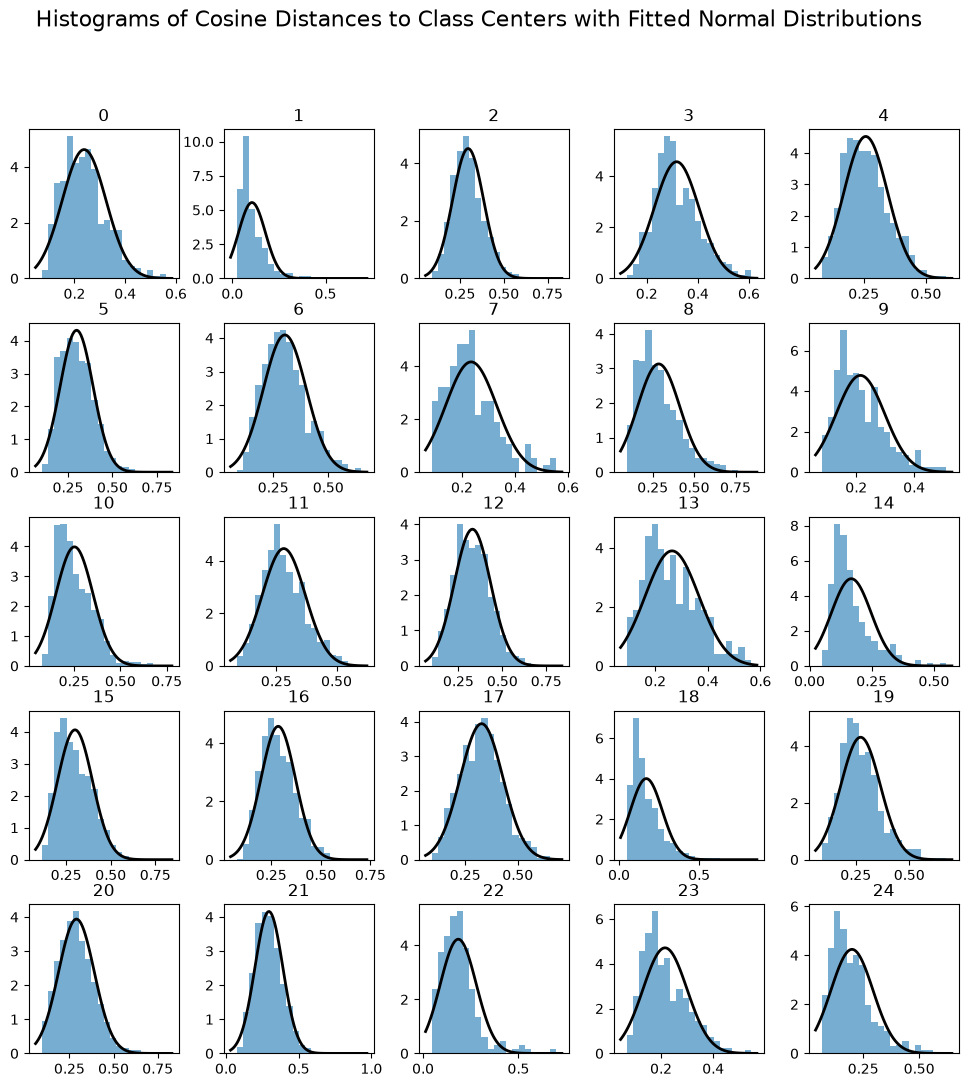

In [20]:
# Check if distances are normally distributed for each class
centers = class_centers(X_train, y_train) 
distances_per_class = get_cosine_distances_to_class_centers(X_train, y_train, centers)

plt.figure(figsize=(12, 12))
plt.suptitle("Histograms of Cosine Distances to Class Centers with Fitted Normal Distributions", fontsize=16)
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# Plot histograms fo distances for each class as a grid (subplots)
for class_id, distances in distances_per_class.items():
    plt.subplot(5, 5, class_id + 1)
    plt.hist(distances, bins=20, density=True, alpha=0.6)
    
    # Fit a normal distribution to the data
    mu, std = norm.fit(distances)
    
    # Plot the PDF of the fitted normal distribution
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = norm.pdf(x, mu, std)
    plt.plot(x, p, 'k', linewidth=2)
    
    plt.title(class_id)

We can see that the distances to the class centers are mostly following normal distributions. Not all perfectly though. 
Some classes are more closely clustered than others. 

1-cosine simmilarity results in a range of [0,2], where 0 indicates identical vectors and 2 indicates vectors pointing in the opposite directions.

In [ ]:
# p value of a prediction based on class distribution stats 
def compute_p_value(predicted_class, sample_embedding, class_distribution_stats):
    """Compute the p-value of a prediction based on class distribution stats."""
    mean_distance, std_distance, center = class_distribution_stats[predicted_class]
    distance = cosine_distance(sample_embedding, center)
    
    # Compute the z-score
    z_score = (distance - mean_distance) / std_distance
    
    # Compute the p-value from the z-score
    p_value = 1 - norm.cdf(z_score)  # One-tailed test
    return p_value

In [13]:
# for a sample prediction 
compute_p_value(predicted_class=y_pred[0], sample_embedding=X_val[0], class_distribution_stats=class_distribution_stats)

np.float64(0.7936512399816011)

In [29]:
def flag_prediction_based_on_p_value(predicted_class, sample_embedding, class_distribution_stats, alpha=0.05):
    """Flag a prediction as potentially incorrect based on its p-value."""
    p_value = compute_p_value(predicted_class, sample_embedding, class_distribution_stats)
    return p_value < alpha, p_value  # Flag if p-value is less than the significance level

In [ ]:
alpha = 0.1  # Significance level for flagging predictions

for X_sample, y_sample in list(zip(X_val, y_val))[:15]:
    predicted_class = model.predict([X_sample])[0]
    is_flagged, p_value = flag_prediction_based_on_p_value(predicted_class, X_sample, class_distribution_stats, alpha)
    print(f"True class: {y_sample}, Predicted class: {predicted_class}, \tFlagged: {is_flagged}, \tP-value: {p_value:.4f}")

True class: 15, Predicted class: 15, 	Flagged: False, 	P-value: 0.7936512399816011
True class: 17, Predicted class: 17, 	Flagged: False, 	P-value: 0.6647056471390366
True class: 24, Predicted class: 24, 	Flagged: False, 	P-value: 0.40925028963186616
True class: 21, Predicted class: 21, 	Flagged: False, 	P-value: 0.9174751604850978
True class: 15, Predicted class: 15, 	Flagged: True, 	P-value: 0.05072666343165222
True class: 23, Predicted class: 23, 	Flagged: False, 	P-value: 0.7746619618163746
True class: 23, Predicted class: 23, 	Flagged: False, 	P-value: 0.7333613246345577
True class: 21, Predicted class: 2, 	Flagged: False, 	P-value: 0.6388295747640058
True class: 20, Predicted class: 20, 	Flagged: False, 	P-value: 0.43593957601778743
True class: 20, Predicted class: 4, 	Flagged: False, 	P-value: 0.5560732595788256
True class: 5, Predicted class: 5, 	Flagged: False, 	P-value: 0.8845771994058402
True class: 2, Predicted class: 21, 	Flagged: False, 	P-value: 0.5506383609095424
True cl

## Get confidence measures from our models

To optimize the confidence_score metric, the models accuracy should be equal to its predicted probability (for predictions it predicts with 80% probability, it should also be correct 80% of the time) _and_ take into account the difficulty of the prediction.
A harder sample should get a lower confidence score than an easy one. 

The confidence measures below give a confidence value for the prediction, taking different approaches to do that.
Most of them check for the probability distribution of the labels and check how confident the model was in making the final argmax prediction.


However, to get the best possible score on the confidence_score metric these are not necessarily the right ones


Assumption: a classifier that outputs probabilities per class

- Highest probabilty
- Difference between top2, inverted top2 ratio
- Shannon Entropy
- Multinomial Classification Certainty (MCC)
All measures are oriented so higher means more confident. Only the highest probability is directly intended as an estimate of correctness; the other measures describe the shape of the probability distribution and are not calibrated probabilities or p-values.



From https://link.springer.com/article/10.1007/s13748-025-00404-w

$$\mathrm{MCC} = 1 - \frac{p_2}{n\,p_1^2}$$

Here $p_1$ and $p_2$ are the highest and second-highest class probabilities, and $n$ is the number of classes. We apply this to the model's probabilities. For normalized probabilities with at least two classes, the predicted-class score ranges from 0 (uniform) to 1 (certain).

It rather describes the dominance of the top prediction over the others, taking into account some additional factors.
Thats why it is not the probability of being correct.

In [6]:
def confidence_highest_probability(y_probs):
    # The highest probability.
    return np.max(y_probs, axis=1)


def confidence_difference_top_2(y_probs):
    # Highest probability minus the second highest.
    top_two = np.sort(y_probs, axis=1)[:, -2:]
    return top_two[:, 1] - top_two[:, 0]


def confidence_ratio_top_2(y_probs):
    # One minus second / first, so higher means more confident.
    top_two = np.sort(y_probs, axis=1)[:, -2:]
    return 1 - top_two[:, 0] / top_two[:, 1]


def confidence_shannon_entropy(y_probs):
    # Purity of the probability distribution.
    # Use masked log to handle zero probabilities without log(0) warnings.
    log_probs = np.zeros_like(y_probs)
    np.log(y_probs, out=log_probs, where=y_probs > 0)
    entropy = -np.sum(y_probs * log_probs, axis=1)
    return np.clip(1 - entropy / np.log(y_probs.shape[1]), 0, 1)


def confidence_multinomial_classification_confidence(y_probs):
    # Paper's MCC for the predicted class.
    top_two = np.sort(y_probs, axis=1)[:, -2:]
    return 1 - top_two[:, 0] / (y_probs.shape[1] * top_two[:, 1] ** 2)


def assess_prediction_confidence(y_probs:np.ndarray):
    """
    Return predicted probability-column indices and confidence measures per sample.
    """

    return pd.DataFrame({
        "predicted_class": y_probs.argmax(axis=1),
        "top1": confidence_highest_probability(y_probs),
        "diff-top-2": confidence_difference_top_2(y_probs),
        "ratio-top-2": confidence_ratio_top_2(y_probs),
        "entropy": confidence_shannon_entropy(y_probs),
        "mcc": confidence_multinomial_classification_confidence(y_probs),
    })


sanity checks / examples

In [7]:
example_probs = np.array([[1/3, 1/3, 1/3], [1., 0., 0.], [0.6, 0.3, 0.1], [0.5, 0.5, 0.0]])
example_confidence = assess_prediction_confidence(example_probs)
confidence_columns = example_confidence.columns.drop("predicted_class")
display("examples of confidence measures with different distributions")
display(example_confidence.round(4))

# confidence scores as calculated by the different measures
prediction_confidence = assess_prediction_confidence(y_probs)
display("confidence scores for the validation set")
display(prediction_confidence.head().round(4))

# confidence_score metric using the different confidence measures
y_pred = model.classes_[prediction_confidence["predicted_class"].to_numpy()]
conf_score_by_conf_measure = pd.Series({
    name: confidence_score(y_val, y_pred, prediction_confidence[name])
    for name in confidence_columns
}, name="confidence_score")
display("confidence_score using the different confidence measures. ")
display(conf_score_by_conf_measure.sort_values(ascending=False).round(4).to_frame())


'examples of confidence measures with different distributions'

,predicted_class,top1,diff-top-2,ratio-top-2,entropy,mcc
0,0,0.3333,0.0,0.0,0.0000,0.0000
1,0,1.0000,1.0,1.0,1.0000,1.0000
2,0,0.6000,0.3,0.5,0.1827,0.7222
3,0,0.5000,0.0,0.0,0.3691,0.3333


'confidence scores for the validation set'

,predicted_class,top1,diff-top-2,ratio-top-2,entropy,mcc
0,15,0.8919,0.8674,0.9725,0.8080,0.9988
1,17,0.7063,0.5755,0.8148,0.6687,0.9895
2,24,0.8674,0.8247,0.9508,0.7782,0.9977
3,21,0.5321,0.3268,0.6142,0.5503,0.9710
4,15,0.4170,0.2445,0.5864,0.3854,0.9603


'confidence_score using the different confidence measures. '

,confidence_score
top1,0.6226
entropy,0.6153
ratio-top-2,0.6140
diff-top-2,0.5852
mcc,0.5689


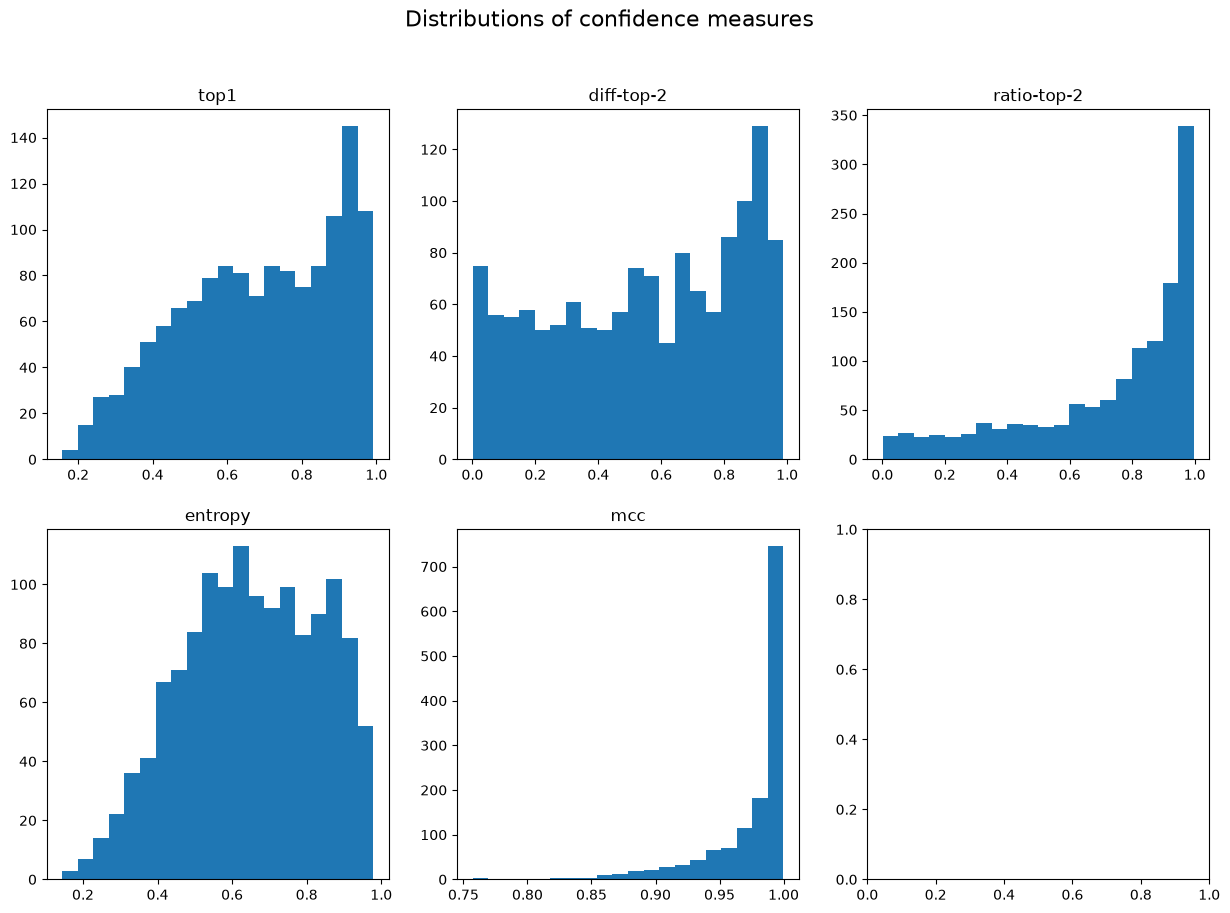

In [31]:

confidence_columns = assess_prediction_confidence(y_probs)
confidence_columns = confidence_columns.columns.drop("predicted_class")
# plot the distributions of all confidence measures one subplot per measure
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10))
fig.suptitle("Distributions of confidence measures", fontsize=16)
for ax, name in zip(axes.flatten(), confidence_columns):
    ax.hist(prediction_confidence[name], bins=20)
    ax.set_title(name)


mcc has almos all predictions close to 1.
This is a result of the denominator blowing up. E.g. when $p_1=0.8$ and Nr of classes = 25 then.
$$\text{Denominator} = 25 \times 0.64 = 16.0$$
MCC is heavily sensitive to the number of classes ($C$) and is a better indicator of confidence for fewer classes.

For that reason it is not used further.

### Conclusion

These confidence measures are usefull if we actually want to assess the models predictions in a more general sense (how much more mass is put on the top-1 prediction, what is the gap to the next most likely one etc.).

However, to optimize the metric we are given, later we will use the plain max probability as the confidence. We just need to make sure it is calibrated.

## Flag uncertain predictions for potential human review

Flag predictions with maximum probability below **0.5**, or where the margin between the probabilities for the top two predictions is < 0.1 or where the set size of the 90% conformal prediction set is greater than 1.

For a flagged sample, we also display the 90% conformal prediction set to speed up the review process.

### Conformal prediction sets
In the predicition set for a sample x is:
$$
C(x)=\{y:1-\hat p(y\mid x)\le q\}.
$$
q cutoff



The idea behind this technique is that instead of predicting a single class, a set of classes are predicted for each sample. This set should include the true lable with a set probability 1-alpha:

The size of this set also tells us a bit about the uncertainty in the prediction. If it is big, then a lot of different classes have been assigned some amount of probability.

1. Get the predictions probabilities on the calibrations set. now 1 - probability_of_the_true_class are the calibation scores
2. Now sort that list and check what was the predicted probability for the sample at the cutoff -> 0.92 that means the lowest prediction for the true label in the best 90% was 8%. 
3. Now assuming that the data is simmilar. We say that if a predictions probability is greater than 8%,then it could be a true label and is included in the prediction set.

Calculate cutoff on calibration set

In [29]:
# Fraction of samples who's true label is not in the prediction set. alpha = 0.1
alpha = 0.1
# Get 1-probability of the true label for each sample. high -> bad, low -> good
calibration_probs = model.predict_proba(X_cal)
calibration_scores = 1 - calibration_probs[np.arange(len(y_cal)), y_cal]

# sort smalles to largest (best to worst)
sorted_scores = np.sort(calibration_scores)
# take the score of the sample at the rank. e.g. 0.92 = 1- y_prob_true_label
cutoff_id = int(np.ceil((len(y_cal) + 1) * (1 - alpha))) 
cutoff = sorted_scores[cutoff_id - 1]


#If the probability of a class is greater than the cutoff, it is included in the prediction set.
def conformal_prediction(y_probs, cutoff):
    in_prediction_set = (1 - y_probs) <= cutoff
    industry_names = label_encoder.inverse_transform(model.classes_)
    prediction_sets = [industry_names[row].tolist() for row in in_prediction_set]
    return in_prediction_set, prediction_sets

print("Example of conformal prediction sets")
in_prediction_set, prediction_sets = conformal_prediction(y_probs, cutoff)
prediction_sets[:2]

Example of conformal prediction sets


[['Materials'],
 ['Health Care Equipment & Services',
  'Household & Personal Products',
  'Pharmaceuticals, Biotechnology & Life Sciences']]

### Flag uncertain predictions

In [35]:
# Configuration
LOW_PROBABILITY_THRESHOLD = 0.5 # flag predictions with max probability below threshold
SET_SIZE_THRESHOLD = 1 # flag prediction sets with size > threshold. 
MARGIN_THRESHOLD = 0.1 # flag predictions with margin between top 2 classes below threshold

def flag_uncertain_predictions(y_probs, prediction_sets):
    # flag predictions with max probability below threshold
    # We could use a differen confidence measure here. 
    confidence = y_probs.max(axis=1)
    low_confidence = confidence < LOW_PROBABILITY_THRESHOLD

    # We also flag for review if the margin between the top 2 predictions is too small
    margin = confidence_difference_top_2(y_probs)
    small_margin = margin < MARGIN_THRESHOLD

    # flag predictions with a conformal set size not equal to 1
    set_sizes = np.array([len(s) for s in prediction_sets])
    conformal_review = set_sizes > SET_SIZE_THRESHOLD

    # review if the confidence is to low, margin is too small or the conformal prediction set size is too large
    needs_review = (low_confidence 
        | small_margin 
        | conformal_review
    ) 
    covered = in_prediction_set[np.arange(len(y_val)), y_val]

    conformal_results = pd.DataFrame({
        "id_val": df_val.index,
        "true_industry": label_encoder.inverse_transform(y_val),
        "predicted_industry": label_encoder.inverse_transform(y_pred),
        "confidence": confidence,
        "prediction_set": prediction_sets,
        "set_size": set_sizes,
        "low_confidence_flag": low_confidence,
        "prediction_set_size_flag": conformal_review,
        "needs_review_flag": needs_review,
    })
    review_queue = conformal_results[conformal_results["needs_review_flag"]]

    review_summary = pd.DataFrame({
        "needs_review": needs_review,
        "correct": y_pred == y_val,
    }).groupby("needs_review").agg(count=("correct", "size"), accuracy=("correct", "mean"))
    display("number of samples flagged for human review and the accuracy of the predictions on them (based on their max probability prediction)")
    display(review_summary)
    display("first 5 samples in the review queue")
    display(review_queue.head())


    print("Flagged for review:")
    print(f"Config: Low probability threshold: {LOW_PROBABILITY_THRESHOLD} and prediction set size threshold: {SET_SIZE_THRESHOLD}")
    print(f"Target coverage: {1 - alpha:.1%}; observed coverage: {covered.mean():.1%}")
    print(f"Average set size: {set_sizes.mean():.2f}")
    print(f"Below probability threshold (samples flagged based on low max probability) {LOW_PROBABILITY_THRESHOLD}: {low_confidence.mean():.1%}")
    print(f"Percent of conformal prediction sets with set size > 1: {conformal_review.mean():.1%}")
    print(f"Percent of samples flagged for human review: {needs_review.mean():.1%}")
    print(f"Review queue size: {len(review_queue)} ({len(review_queue) / len(y_val):.1%} of predictions need to be reviewed)")

    return review_queue

review_queue = flag_uncertain_predictions(y_probs, prediction_sets)


'number of samples flagged for human review and the accuracy of the predictions on them (based on their max probability prediction)'

,count,accuracy
needs_review,,
False,509,0.91945
True,848,0.64033


'first 5 samples in the review queue'

,id_val,true_industry,predicted_industry,confidence,prediction_set,set_size,low_confidence_flag,prediction_set_size_flag,needs_review_flag
1,32174,"Pharmaceuticals, Biotechnology & Life Sciences","Pharmaceuticals, Biotechnology & Life Sciences",0.706344,"[Health Care Equipment & Services, Household &...",3,False,True,True
3,7277,Technology Hardware & Equipment,Technology Hardware & Equipment,0.532076,"[Capital Goods, Semiconductors & Semiconductor...",3,False,True,True
4,11222,Materials,Materials,0.417030,"[Materials, Semiconductors & Semiconductor Equ...",3,True,True,True
5,23303,Transportation,Transportation,0.705142,"[Consumer Services, Transportation]",2,False,True,True
7,616,Technology Hardware & Equipment,Capital Goods,0.449629,"[Capital Goods, Consumer Durables & Apparel, T...",3,True,True,True


Flagged for review:
Config: Low probability threshold: 0.5 and prediction set size threshold: 1
Target coverage: 90.0%; observed coverage: 90.7%
Average set size: 2.00
Below probability threshold (samples flagged based on low max probability) 0.5: 22.4%
Percent of conformal prediction sets with set size > 1: 62.4%
Percent of samples flagged for human review: 62.5%
Review queue size: 848 (62.5% of predictions need to be reviewed)


## Analyze the relationship between statistical confidence and classification accuracy

We can plot the confidence and accuracy of predictions against each other


Weighted F1: 		0.7415
Brier: 			0.1604
Combined score: 	0.6226
Mean confidence: 	0.6823
Accuracy: 		0.7450


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",4,0.161145,0.750000
"(0.2, 0.3]",50,0.255893,0.220000
"(0.3, 0.4]",102,0.355382,0.392157
"(0.4, 0.5]",148,0.451851,0.601351
"(0.5, 0.6]",182,0.551816,0.670330
"(0.6, 0.7]",187,0.647170,0.727273
"(0.7, 0.8]",197,0.750396,0.776650
"(0.8, 0.9]",215,0.854393,0.906977
"(0.9, 1.0]",272,0.942587,0.963235


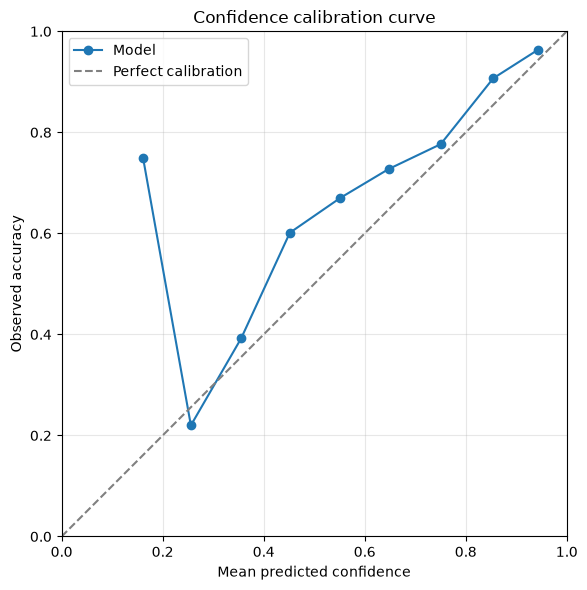

In [36]:
def evaluate_model(model, X_val, y_val):
        
    proba = model.predict_proba(X_val)
    y_pred = model.classes_[proba.argmax(axis=1)]
    confidence = proba.max(axis=1)

    correct = (y_pred == y_val).astype(float)
    f1 = f1_score(y_val, y_pred, average="weighted")
    brier = np.mean((confidence - correct) ** 2)

    print(f"Weighted F1: \t\t{f1:.4f}")
    print(f"Brier: \t\t\t{brier:.4f}")
    print(f"Combined score: \t{f1 * (1 - brier):.4f}")
    print(f"Mean confidence: \t{confidence.mean():.4f}")
    print(f"Accuracy: \t\t{correct.mean():.4f}")


    # Compare confidence with observed accuracy within each bin.
    calibration = pd.DataFrame({
        "confidence": confidence,
        "correct": correct,
    })

    # Calculate means per bin. 
    calibration["bin"] = pd.cut(
        calibration["confidence"],
        bins=np.linspace(0, 1, 11),
        include_lowest=True,
    )

    calibration_stats = calibration.groupby("bin", observed=True).agg(
        count=("correct", "size"),
        mean_confidence=("confidence", "mean"),
        accuracy=("correct", "mean"),
    )
    display(calibration_stats)
    fig, ax = plt.subplots(figsize=(8, 6))

    ax.plot(
        calibration_stats["mean_confidence"],
        calibration_stats["accuracy"],
        marker="o",
        label="Model",
    )
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")

    ax.set(
        xlabel="Mean predicted confidence",
        ylabel="Observed accuracy",
        title="Confidence calibration curve",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()
evaluate_model(model, X_val, y_val)

A perfectly calibrated model would have accuracy equal to confidence (probability for the choosen class).

The Models line being over the dashed line indicates, that the model is more accurate than it is confidence -> it is _underconfident_.

Luckily this can be adjusted

Weighted F1: 		0.7415
Brier: 			0.1558
Combined score: 	0.6260
Mean confidence: 	0.7361
Accuracy: 		0.7450


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",4,0.180663,0.750000
"(0.2, 0.3]",26,0.261514,0.192308
"(0.3, 0.4]",72,0.351680,0.416667
"(0.4, 0.5]",113,0.450036,0.469027
"(0.5, 0.6]",151,0.547270,0.582781
"(0.6, 0.7]",172,0.651646,0.703488
"(0.7, 0.8]",190,0.751212,0.715789
"(0.8, 0.9]",216,0.850440,0.861111
"(0.9, 1.0]",413,0.954074,0.941889


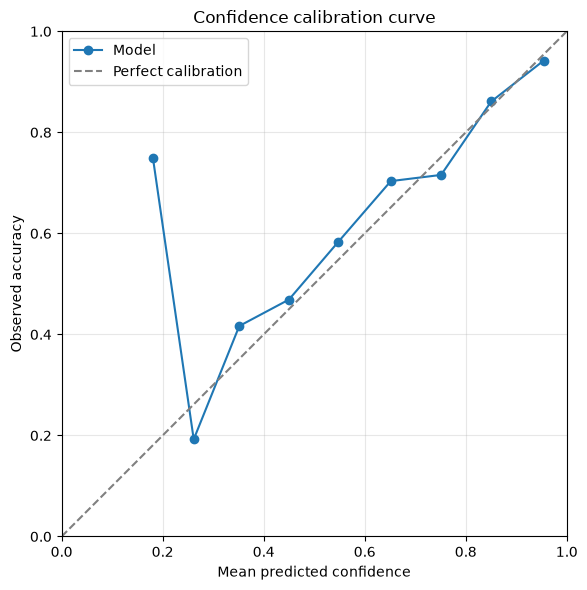

In [ ]:


calibrated_classifier = CalibratedClassifierCV(
    estimator=FrozenEstimator(model),
    method="temperature",
)
calibrated_classifier.fit(X_cal, y_cal)


evaluate_model(calibrated_classifier, X_val, y_val)




Although also not perfect, the accuracy is more equal to the confidence resulting in a more calibrated model.

## Classifier that beats the plain logistic regression

Weighted F1: 		0.7450
Brier: 			0.1613
Combined score: 	0.6248
Mean confidence: 	0.6488
Accuracy: 		0.7472


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",11,0.174798,0.090909
"(0.2, 0.3]",62,0.258310,0.290323
"(0.3, 0.4]",150,0.353844,0.540000
"(0.4, 0.5]",174,0.453322,0.551724
"(0.5, 0.6]",142,0.550078,0.626761
"(0.6, 0.7]",193,0.653250,0.787565
"(0.7, 0.8]",215,0.749205,0.874419
"(0.8, 0.9]",235,0.854018,0.953191
"(0.9, 1.0]",175,0.940263,0.942857


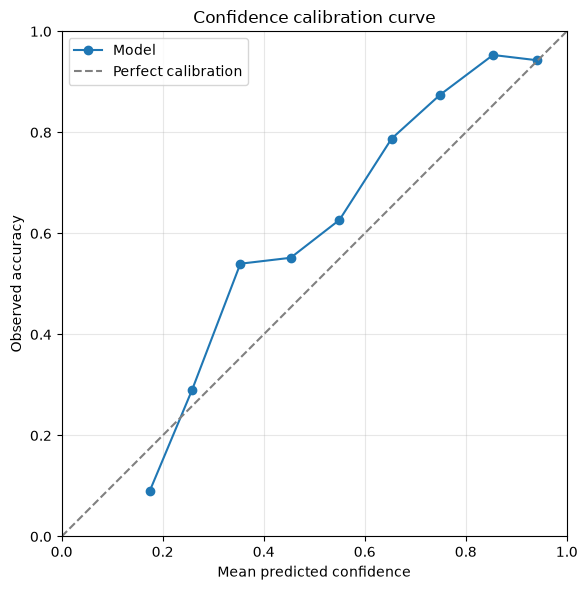

In [155]:
# Make a soft voting ensemble classifier of calibrated classifiers using different models.

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = [
    (
        "logistic",
        make_pipeline(
            StandardScaler(),
            LogisticRegression(C=1.0, max_iter=1000, random_state=42),
        ),
    ),
    (
        "mlp",
        make_pipeline(
            StandardScaler(),
            MLPClassifier(
                hidden_layer_sizes=(128,),
                alpha=1e-3,
                batch_size=512,
                early_stopping=True,
                max_iter=100,
                random_state=42,
            ),
        ),
    ),
    (
        "hist_gradient_boosting",
        HistGradientBoostingClassifier(
            max_iter=150,
            max_leaf_nodes=15,
            min_samples_leaf=50,
            l2_regularization=1.0,
            early_stopping=True,
            random_state=42,
        ),
    ),
]

calibrated_models = [
    (
        name,
        CalibratedClassifierCV(
            estimator=model,
            method="temperature",
            cv=3,
            ensemble=False,
        ),
    )
    for name, model in models
]

soft_voting = VotingClassifier(
    estimators=calibrated_models,
    voting="soft",
    n_jobs=1,
)

soft_voting.fit(X_train, y_train)

evaluate_model(soft_voting, X_val, y_val)

Model is underconfident. Need to calibrate final classifier

Weighted F1: 		0.7450
Brier: 			0.1503
Combined score: 	0.6330
Mean confidence: 	0.7307
Accuracy: 		0.7472


,count,mean_confidence,accuracy
bin,,,
"(0.1, 0.2]",5,0.182176,0.200000
"(0.2, 0.3]",31,0.262477,0.161290
"(0.3, 0.4]",80,0.352901,0.425000
"(0.4, 0.5]",149,0.453537,0.536913
"(0.5, 0.6]",136,0.550917,0.580882
"(0.6, 0.7]",114,0.644778,0.587719
"(0.7, 0.8]",189,0.754197,0.767196
"(0.8, 0.9]",260,0.851075,0.888462
"(0.9, 1.0]",393,0.952937,0.946565


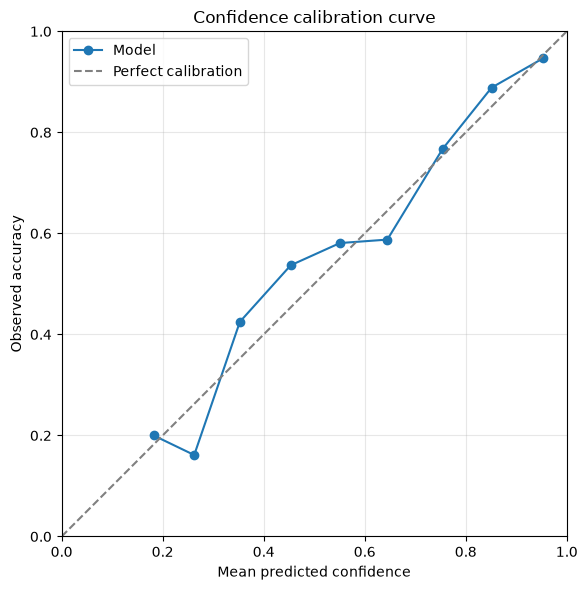

In [156]:
# adjust probabilities.
calibrated_voting = CalibratedClassifierCV(
    estimator=FrozenEstimator(soft_voting),
    method="temperature",
)

calibrated_voting.fit(X_cal, y_cal)
evaluate_model(calibrated_voting, X_val, y_val)

### Iteratively training classifiers on the samples that previous rounds made errors on

In [33]:
from sklearn.ensemble import StackingClassifier

In [ ]:
def fit_iterative_error_stack(
    X_train,
    y_train,
    X_meta,
    y_meta,
    max_rounds=5,
    min_samples=50,
):
    """Fit one cheap classifier per round, then stack their predictions.

    The next round only sees samples misclassified by the preceding round.
    The meta-estimator is fitted on a separate calibration split so it does
    not learn from the same predictions used to fit the round classifiers.
    """
    round_models = []
    round_sizes = []
    current_indices = np.arange(len(y_train))

    for round_number in range(max_rounds):
        if len(current_indices) < min_samples:
            break

        X_round = X_train[current_indices]
        y_round = y_train[current_indices]
        if np.unique(y_round).size < 2:
            print(f"Stopping before round {round_number + 1}: only one class remains.")
            break

        model = LogisticRegression(max_iter=200, solver="lbfgs")
        model.fit(X_round, y_round)
        predictions = model.predict(X_round)
        errors = predictions != y_round

        round_models.append(model)
        round_sizes.append(len(current_indices))
        print(
            f"Round {round_number + 1}: trained on {len(current_indices)} samples; "
            f"errors = {errors.sum()}"
        )

        if not errors.any():
            break
        current_indices = current_indices[errors]

    if not round_models:
        raise ValueError("No round classifier could be fitted; lower min_samples or check labels.")

    stack = StackingClassifier(
        estimators=[
            (f"round_{i + 1}", model) for i, model in enumerate(round_models)
        ],
        final_estimator=LogisticRegression(max_iter=200, solver="lbfgs"),
        stack_method="predict_proba",
        cv="prefit",
    )
    stack.fit(X_meta, y_meta)
    stack.round_sizes_ = np.asarray(round_sizes)
    return stack


iterative_stack = fit_iterative_error_stack(
    X_train,
    y_train,
    X_cal,
    y_cal,
    max_rounds=5,
    min_samples=50,
)
print(f"Round sizes: {iterative_stack.round_sizes_.tolist()}")
evaluate_model(iterative_stack, X_val, y_val)

Round 1: trained on 24414 samples; errors = 5921
Round 2: trained on 5921 samples; errors = 4027
Round 3: trained on 4027 samples; errors = 3205
Round 4: trained on 3205 samples; errors = 2745
Round 5: trained on 2745 samples; errors = 2437
Round sizes: [24414, 5921, 4027, 3205, 2745]


NameError: name 'evaluate_model' is not defined